# Modélisation — Prédiction bénin / malin (`Prostate_Cancer.csv`)

**Objectif :** prédire si une tumeur est **maligne (M)** ou **bénigne (B)** afin d'**éviter des biopsies inutiles**.

Traduit en exigence de modèle :
- **ne presque jamais rater un cancer** → sensibilité (rappel sur M) très élevée ;
- **sous cette contrainte**, écarter le plus possible de bénins → spécificité = part des biopsies inutiles évitées.

**Choix issus de l'EDA** (voir `eda_prostate_cancer.ipynb`) :
- `radius` et `texture` sont exclues (valeurs incohérentes, apparemment aléatoires) ; `id` aussi.
- Le fichier est trié selon la cible → découpages **mélangés et stratifiés**.
- n = 100 → validation croisée **répétée**, modèles simples privilégiés.

**Plan**
1. Préparation et découpage train / test
2. Comparaison de modèles (validation croisée)
3. Impact de l'exclusion de `radius` / `texture`
4. Optimisation des hyperparamètres
5. Évaluation finale sur le jeu de test
6. Choix d'un seuil clinique (éviter des biopsies sans rater de cancer)
7. Interprétation du modèle
8. Conclusion et limites

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import (train_test_split, RepeatedStratifiedKFold,
                                     StratifiedKFold, cross_validate, GridSearchCV,
                                     cross_val_predict)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report,
                             recall_score, accuracy_score, f1_score)
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
SEED = 42

## 1. Préparation et découpage train / test

In [2]:
df = pd.read_csv("../data/Prostate_Cancer.csv")

FEATURES = ["perimeter", "area", "smoothness", "compactness", "symmetry", "fractal_dimension"]
X = df[FEATURES]
y = (df["diagnosis_result"] == "M").astype(int)   # 1 = malin, 0 = bénin

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, shuffle=True, random_state=SEED)

print(f"Train : {len(X_train)} patients  ({y_train.mean():.0%} de malins)")
print(f"Test  : {len(X_test)} patients  ({y_test.mean():.0%} de malins)")

Train : 75 patients  (63% de malins)
Test  : 25 patients  (60% de malins)


Le jeu de **test (25 patients)** est mis de côté et ne sera utilisé **qu'une seule fois**, à la fin. Toutes les comparaisons et réglages se font par validation croisée sur le train (75 patients).

## 2. Comparaison de modèles (validation croisée répétée)

Validation croisée stratifiée à 5 plis, répétée 10 fois (= 50 évaluations par modèle), pour obtenir des scores stables malgré le petit échantillon. Les modèles sensibles à l'échelle sont précédés d'une standardisation, **dans le pipeline** (pas de fuite d'information du test vers le train).

In [3]:
log_tf = FunctionTransformer(np.log)   # toutes les variables sont > 0

modeles = {
    "Référence (classe majoritaire)": DummyClassifier(strategy="most_frequent"),
    "Régression logistique": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Régression logistique (log)": make_pipeline(log_tf, StandardScaler(), LogisticRegression(max_iter=1000)),
    "KNN (k=7)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7)),
    "SVM (RBF)": make_pipeline(StandardScaler(), SVC(probability=True, random_state=SEED)),
    "Arbre de décision": DecisionTreeClassifier(max_depth=3, random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=SEED),
    "Gradient Boosting": GradientBoostingClassifier(random_state=SEED),
}

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)
scoring = {"AUC": "roc_auc", "Accuracy": "accuracy", "Sensibilité": "recall", "F1": "f1"}

resultats, auc_par_pli = {}, {}
for nom, m in modeles.items():
    r = cross_validate(m, X_train, y_train, cv=cv, scoring=scoring)
    resultats[nom] = {k: r[f"test_{k}"].mean() for k in scoring}
    resultats[nom]["AUC écart-type"] = r["test_AUC"].std()
    auc_par_pli[nom] = r["test_AUC"]

tab = pd.DataFrame(resultats).T.sort_values("AUC", ascending=False)
tab.style.format("{:.3f}").background_gradient(subset=["AUC"], cmap="Greens")

,AUC,Accuracy,Sensibilité,F1,AUC écart-type
SVM (RBF),0.915,0.853,0.920,0.887,0.067
Random Forest,0.896,0.809,0.865,0.851,0.074
Régression logistique (log),0.893,0.827,0.912,0.868,0.100
Régression logistique,0.886,0.835,0.900,0.872,0.107
KNN (k=7),0.884,0.863,0.922,0.894,0.095
Gradient Boosting,0.883,0.805,0.881,0.850,0.085
Arbre de décision,0.814,0.789,0.833,0.829,0.121
Référence (classe majoritaire),0.500,0.627,1.000,0.770,0.000


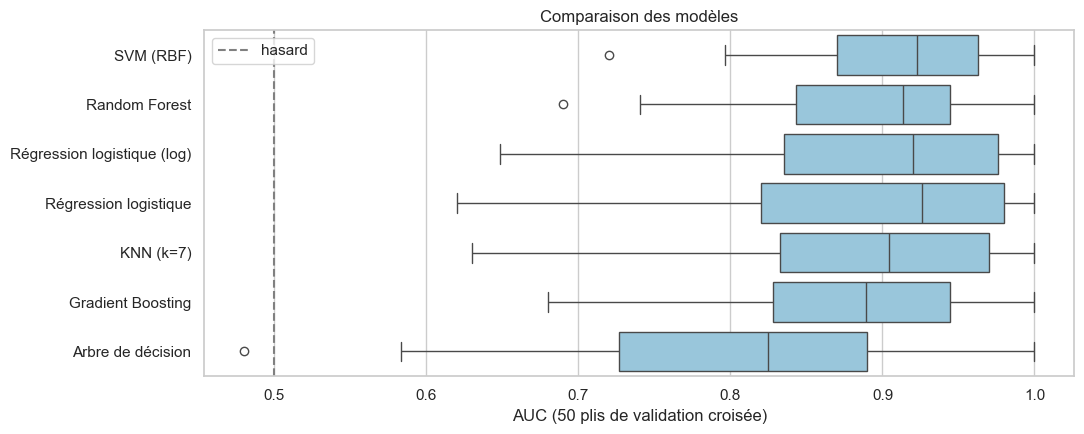

In [4]:
ordre = tab.index.drop("Référence (classe majoritaire)")
plt.figure(figsize=(11, 4.5))
sns.boxplot(data=pd.DataFrame(auc_par_pli)[ordre], orient="h", color="#8ecae6")
plt.axvline(0.5, ls="--", c="grey", label="hasard")
plt.xlabel("AUC (50 plis de validation croisée)"); plt.title("Comparaison des modèles")
plt.legend(); plt.tight_layout(); plt.show()

**Lecture :**
- La référence (toujours prédire « malin ») a une accuracy ≈ 62 % mais une AUC de 0,5 : elle ne discrimine rien. Tout modèle doit faire nettement mieux.
- Le **SVM** arrive en tête (AUC ≈ 0,92). Random Forest, régression logistique, KNN et Gradient Boosting sont groupés autour de 0,88–0,90 : leurs écarts sont **bien inférieurs à l'écart-type** (≈ 0,07–0,10), donc non significatifs.
- L'**arbre de décision seul** est nettement en dessous (≈ 0,81) : avec 75 patients, il sur-apprend.
- Les modèles complexes (boosting, forêts) **n'apportent rien** par rapport aux modèles simples sur un échantillon aussi petit.
- La dispersion des AUC entre plis est importante : avec ~15 patients par pli, il faut rester prudent sur les écarts de quelques centièmes.

## 3. Impact de l'exclusion de `radius` / `texture`

In [5]:
variantes = {
    "6 variables fiables": FEATURES,
    "+ radius et texture (8 variables)": ["radius", "texture"] + FEATURES,
    "sans area (redondante avec perimeter)": [f for f in FEATURES if f != "area"],
    "radius + texture seuls": ["radius", "texture"],
}
idx_train = X_train.index
modele_ref = make_pipeline(log_tf, StandardScaler(), LogisticRegression(max_iter=1000))
res = {}
for nom, cols in variantes.items():
    r = cross_validate(modele_ref, df.loc[idx_train, cols], y_train, cv=cv, scoring="roc_auc")
    res[nom] = {"AUC moyenne": r["test_score"].mean(), "écart-type": r["test_score"].std()}
pd.DataFrame(res).T.style.format("{:.3f}")

,AUC moyenne,écart-type
6 variables fiables,0.893,0.100
+ radius et texture (8 variables),0.877,0.108
sans area (redondante avec perimeter),0.898,0.095
radius + texture seuls,0.582,0.138


➡️ Ajouter `radius` et `texture` **dégrade légèrement** le modèle (0,893 → 0,877), et seules elles prédisent à peine mieux que le hasard (AUC ≈ 0,58). Cela confirme l'EDA : on les laisse de côté. Retirer `area` change très peu (redondance avec `perimeter`) ; on la garde car la régularisation gère cette colinéarité.

## 4. Optimisation des hyperparamètres

On règle les deux meilleurs modèles par recherche sur grille (validation croisée stratifiée sur le train) :
- **Régression logistique (log)** : force de régularisation `C`, type de pénalité (L1 = Lasso, L2 = Ridge) ;
- **SVM** : `C` et `gamma`.

In [6]:
cv_grid = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)

grid_lr = GridSearchCV(
    make_pipeline(log_tf, StandardScaler(), LogisticRegression(solver="liblinear", max_iter=1000)),
    {"logisticregression__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30],
     "logisticregression__penalty": ["l1", "l2"]},
    cv=cv_grid, scoring="roc_auc").fit(X_train, y_train)

grid_svm = GridSearchCV(
    make_pipeline(StandardScaler(), SVC(probability=True, random_state=SEED)),
    {"svc__C": [0.1, 0.3, 1, 3, 10, 30], "svc__gamma": ["scale", 0.01, 0.03, 0.1, 0.3]},
    cv=cv_grid, scoring="roc_auc").fit(X_train, y_train)

for nom, g in [("Régression logistique", grid_lr), ("SVM", grid_svm)]:
    print(f"{nom:22s} AUC CV = {g.best_score_:.3f}   meilleurs paramètres : {g.best_params_}")

Régression logistique  AUC CV = 0.908   meilleurs paramètres : {'logisticregression__C': 0.3, 'logisticregression__penalty': 'l1'}
SVM                    AUC CV = 0.928   meilleurs paramètres : {'svc__C': 1, 'svc__gamma': 'scale'}


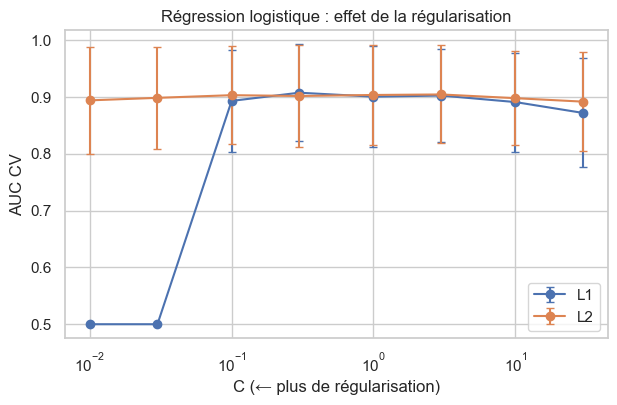

In [7]:
# Visualisation : AUC selon C pour la régression logistique
cvres = pd.DataFrame(grid_lr.cv_results_)
plt.figure(figsize=(7, 4))
for pen, g in cvres.groupby("param_logisticregression__penalty"):
    plt.errorbar(g["param_logisticregression__C"].astype(float), g["mean_test_score"],
                 yerr=g["std_test_score"], marker="o", capsize=3, label=pen.upper())
plt.xscale("log"); plt.xlabel("C (← plus de régularisation)"); plt.ylabel("AUC CV")
plt.title("Régression logistique : effet de la régularisation"); plt.legend(); plt.show()

Le SVM a une AUC CV un peu plus haute (≈ 0,93 contre ≈ 0,91), mais l'écart reste dans la marge d'incertitude. La régression logistique optimale utilise une **pénalité L1 (Lasso) avec C = 0,3** : elle effectue une **sélection automatique de variables** (voir section 7).

On retient la **régression logistique** comme modèle final :
- performance comparable au SVM (et meilleure sur le test, section 5) ;
- **interprétable** (coefficients, odds ratios), ce qui est essentiel en contexte médical ;
- probabilités bien calibrées par construction, utiles pour fixer un seuil clinique.

## 5. Évaluation finale sur le jeu de test

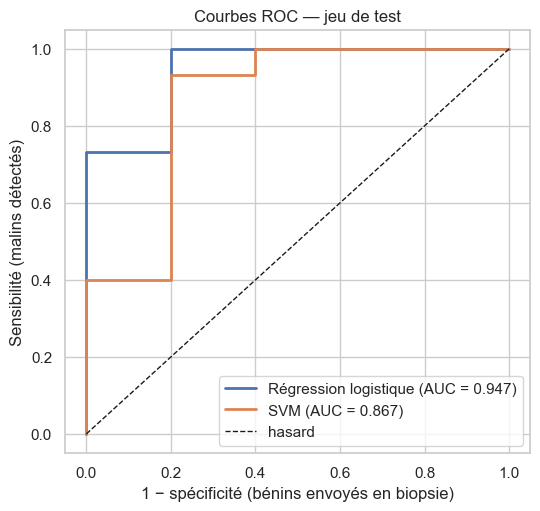

In [8]:
finaux = {"Régression logistique": grid_lr.best_estimator_, "SVM": grid_svm.best_estimator_}

fig, ax = plt.subplots(figsize=(6, 5.5))
for nom, m in finaux.items():
    p = m.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p)
    ax.plot(fpr, tpr, lw=2, label=f"{nom} (AUC = {roc_auc_score(y_test, p):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="hasard")
ax.set(xlabel="1 − spécificité (bénins envoyés en biopsie)", ylabel="Sensibilité (malins détectés)",
       title="Courbes ROC — jeu de test")
ax.legend(loc="lower right"); plt.show()

              precision    recall  f1-score   support

       Bénin      0.889     0.800     0.842        10
       Malin      0.875     0.933     0.903        15

    accuracy                          0.880        25
   macro avg      0.882     0.867     0.873        25
weighted avg      0.881     0.880     0.879        25



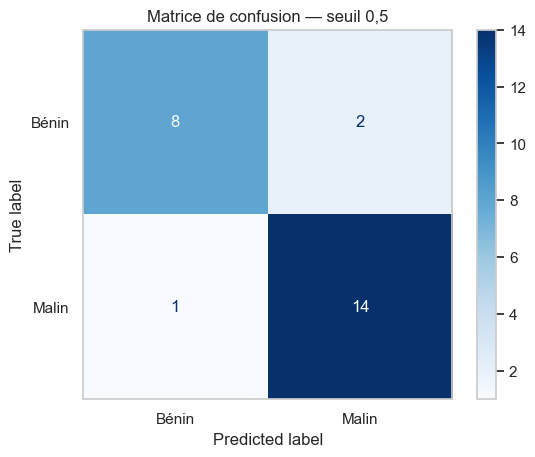

In [9]:
modele = grid_lr.best_estimator_
proba_test = modele.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= 0.5).astype(int)

print(classification_report(y_test, pred_test, target_names=["Bénin", "Malin"], digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_test),
                       display_labels=["Bénin", "Malin"]).plot(cmap="Blues")
plt.title("Matrice de confusion — seuil 0,5"); plt.grid(False); plt.show()

Sur le test, la régression logistique (AUC ≈ 0,95) fait mieux que le SVM (≈ 0,87) : l'ordre est inversé par rapport à la validation croisée, signe que **les deux modèles sont en réalité équivalents** et que le test est trop petit pour les départager. Au seuil 0,5 : 1 cancer raté sur 15, 2 biopsies inutiles sur 10 bénins (accuracy 88 %).

⚠️ Avec seulement 25 patients en test, **un seul patient mal classé fait varier l'accuracy de 4 points**. Les scores de validation croisée (sections 2 et 4) sont donc plus fiables que ce score de test ; le test sert surtout à vérifier l'absence de sur-apprentissage.

## 6. Choix d'un seuil clinique

Le seuil par défaut (0,5) traite de la même façon un faux négatif (cancer **raté**) et un faux positif (biopsie **inutile**). Cliniquement, rater un cancer est bien plus grave.

**Stratégie :** choisir le seuil le plus élevé qui garantit une **sensibilité ≥ 95 %**, puis mesurer combien de biopsies inutiles on évite (spécificité). Le seuil est choisi sur des **prédictions hors-pli du train** (validation croisée), jamais sur le test.

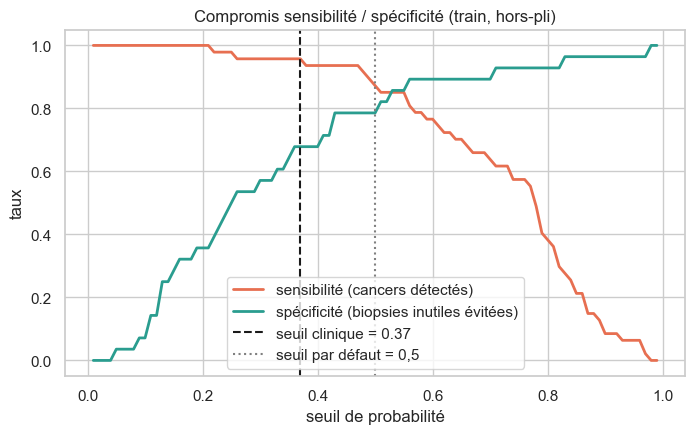

Seuil retenu : 0.37


In [10]:
proba_oof = cross_val_predict(modele, X_train, y_train, method="predict_proba",
                              cv=StratifiedKFold(5, shuffle=True, random_state=SEED))[:, 1]

seuils = np.linspace(0.01, 0.99, 99)
courbe = pd.DataFrame({
    "seuil": seuils,
    "sensibilité": [recall_score(y_train, proba_oof >= s) for s in seuils],
    "spécificité": [recall_score(1 - y_train, proba_oof < s) for s in seuils],
})

CIBLE_SENS = 0.95
seuil_clin = courbe.loc[courbe["sensibilité"] >= CIBLE_SENS, "seuil"].max()

plt.figure(figsize=(8, 4.5))
plt.plot(courbe.seuil, courbe["sensibilité"], label="sensibilité (cancers détectés)", c="#e76f51", lw=2)
plt.plot(courbe.seuil, courbe["spécificité"], label="spécificité (biopsies inutiles évitées)", c="#2a9d8f", lw=2)
plt.axvline(seuil_clin, ls="--", c="k", label=f"seuil clinique = {seuil_clin:.2f}")
plt.axvline(0.5, ls=":", c="grey", label="seuil par défaut = 0,5")
plt.xlabel("seuil de probabilité"); plt.ylabel("taux"); plt.legend(); plt.title("Compromis sensibilité / spécificité (train, hors-pli)")
plt.show()
print(f"Seuil retenu : {seuil_clin:.2f}")

In [11]:
def bilan(y_true, proba, seuil):
    pred = (proba >= seuil).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {"seuil": seuil, "sensibilité": tp / (tp + fn), "spécificité": tn / (tn + fp),
            "cancers ratés (FN)": fn, "biopsies inutiles (FP)": fp,
            "biopsies évitées (VN)": tn, "bénins au total": tn + fp}

pd.DataFrame({
    "seuil 0,5 — test": bilan(y_test, proba_test, 0.5),
    f"seuil clinique {seuil_clin:.2f} — test": bilan(y_test, proba_test, seuil_clin),
    f"seuil clinique {seuil_clin:.2f} — train (hors-pli)": bilan(y_train, proba_oof, seuil_clin),
}).T

,seuil,sensibilité,spécificité,cancers ratés (FN),biopsies inutiles (FP),biopsies évitées (VN),bénins au total
"seuil 0,5 — test",0.50,0.933333,0.800000,1.0,2.0,8.0,10.0
seuil clinique 0.37 — test,0.37,1.000000,0.700000,0.0,3.0,7.0,10.0
seuil clinique 0.37 — train (hors-pli),0.37,0.957447,0.678571,2.0,9.0,19.0,28.0


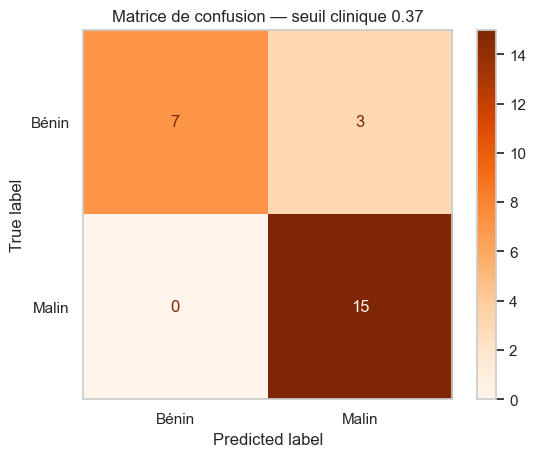

In [12]:
ConfusionMatrixDisplay(confusion_matrix(y_test, (proba_test >= seuil_clin).astype(int)),
                       display_labels=["Bénin", "Malin"]).plot(cmap="Oranges")
plt.title(f"Matrice de confusion — seuil clinique {seuil_clin:.2f}"); plt.grid(False); plt.show()

## 7. Interprétation du modèle
### 7.1 Coefficients et odds ratios
Les variables sont passées au log puis standardisées : un coefficient se lit comme l'effet d'**une augmentation d'un écart-type** (en échelle log) de la variable sur la cote (odds) d'être malin.

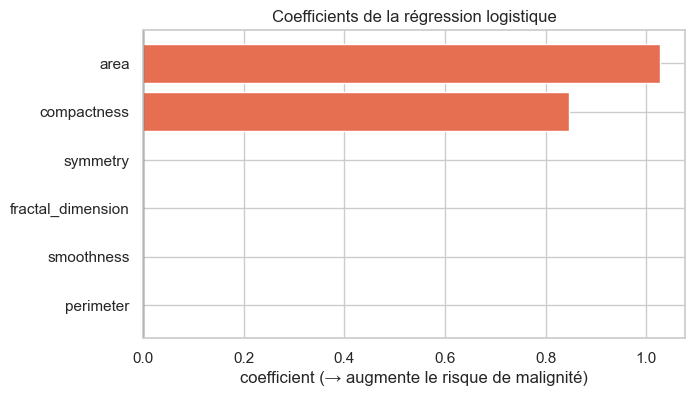

,coefficient,odds ratio
area,1.026196,2.790432
compactness,0.846265,2.330926
smoothness,0.000000,1.000000
perimeter,0.000000,1.000000
symmetry,0.000000,1.000000
fractal_dimension,0.000000,1.000000


In [13]:
lr = modele.named_steps["logisticregression"]
coefs = pd.DataFrame({"coefficient": lr.coef_[0], "odds ratio": np.exp(lr.coef_[0])},
                     index=FEATURES).sort_values("coefficient")

plt.figure(figsize=(7, 4))
plt.barh(coefs.index, coefs["coefficient"],
         color=["#e76f51" if c > 0 else "#2a9d8f" for c in coefs["coefficient"]])
plt.axvline(0, c="k", lw=1)
plt.xlabel("coefficient (→ augmente le risque de malignité)"); plt.title("Coefficients de la régression logistique")
plt.show()
coefs.sort_values("coefficient", ascending=False)

➡️ Le **Lasso n'a gardé que deux variables** : `area` (taille du noyau) et `compactness` (irrégularité de la forme). Toutes les autres ont un coefficient nul :
- `perimeter` est redondante avec `area` (r ≈ 0,98) ;
- `smoothness`, `symmetry`, `fractal_dimension` sont corrélées à `compactness` et n'apportent pas d'information supplémentaire.

Interprétation : une augmentation d'un écart-type de log(area) **multiplie par ≈ 2,8 la cote** de malignité ; pour log(compactness), par ≈ 2,3. On obtient un modèle **très simple, à deux variables**, qui rejoint les deux grandes tendances de l'EDA : **taille** et **forme**.

### 7.2 Importance par permutation (sur le test)

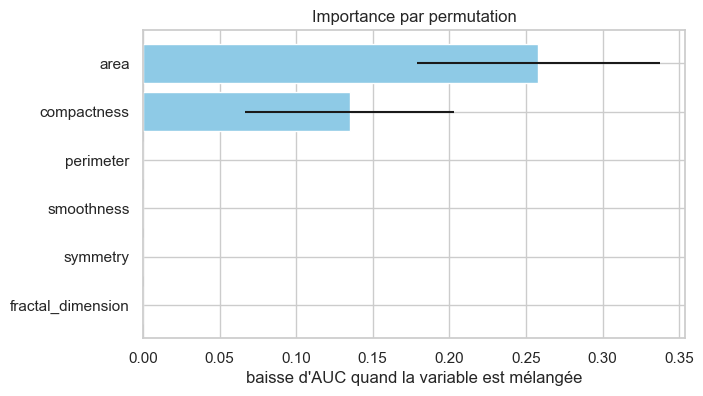

,baisse d'AUC moyenne,écart-type
area,0.258133,0.079140
compactness,0.135067,0.068245
perimeter,0.000000,0.000000
smoothness,0.000000,0.000000
symmetry,0.000000,0.000000
fractal_dimension,0.000000,0.000000


In [14]:
pi = permutation_importance(modele, X_test, y_test, scoring="roc_auc",
                            n_repeats=50, random_state=SEED)
imp = pd.DataFrame({"baisse d'AUC moyenne": pi.importances_mean, "écart-type": pi.importances_std},
                   index=FEATURES).sort_values("baisse d'AUC moyenne", ascending=False)
plt.figure(figsize=(7, 4))
plt.barh(imp.index[::-1], imp["baisse d'AUC moyenne"][::-1], xerr=imp["écart-type"][::-1], color="#8ecae6")
plt.xlabel("baisse d'AUC quand la variable est mélangée"); plt.title("Importance par permutation")
plt.show()
imp

## 8. Conclusion et limites

### Modèle retenu
**Régression logistique pénalisée L1 (Lasso, C = 0,3)** sur variables log-transformées et standardisées. Elle n'utilise en pratique que **2 variables : `area` et `compactness`**.

| | Validation croisée (train) | Test (25 patients) |
|---|---|---|
| AUC | ≈ 0,91 | ≈ 0,95 |
| Accuracy (seuil 0,5) | ≈ 0,83 | 0,88 |
| Sensibilité (seuil 0,5) | ≈ 0,91 | 0,93 |

### Réponse à la question du projet
Avec un **seuil clinique de 0,37** (choisi pour garantir ≈ 95 % de sensibilité) :
- sur le test : **0 cancer raté sur 15**, et **7 biopsies évitées sur 10 patients bénins** (spécificité 70 %) ;
- en validation croisée sur le train : sensibilité ≈ 96 %, spécificité ≈ 68 % (2 cancers ratés sur 47, 19 biopsies évitées sur 28).

➡️ **Oui, le modèle permettrait d'éviter environ deux tiers des biopsies inutiles en ne ratant que très peu de cancers.** Baisser le seuil réduit encore le risque de cancer raté, mais au prix de davantage de biopsies : c'est un **choix clinique**, pas statistique.

### Limites
1. **Très petit échantillon** (100 patients, 25 en test) : les métriques ont une forte incertitude (± 5 à 10 points). Il faudrait une validation sur une cohorte externe plus grande.
2. **Provenance douteuse** du dataset : les variables sont celles du *Breast Cancer Wisconsin* (sein) et deux colonnes (`radius`, `texture`) semblent corrompues. Les conclusions ne sont pas transposables telles quelles à la prostate.
3. Les variables sont des **mesures de noyaux cellulaires sur image de prélèvement** : elles supposent déjà un prélèvement (cytoponction), moins invasif qu'une biopsie mais pas nul.
4. Une sensibilité de 95 % signifie qu'environ **1 cancer sur 20 serait raté** : en pratique, le modèle doit être une **aide à la décision**, pas un remplaçant du jugement médical.

### Pistes d'amélioration
- Validation croisée **imbriquée** (nested CV) pour estimer sans biais la performance après réglage des hyperparamètres.
- **Intervalles de confiance** par bootstrap sur l'AUC, la sensibilité et la spécificité.
- Courbe de **calibration** des probabilités.
- Tester le modèle sur un dataset plus grand (ex. le *Breast Cancer Wisconsin* complet, 569 patients, pour valider la démarche).